# Задание № 3. Прикладные дифференциальные уравнения

## 3.1. Задача о равномерном спуске

Найти такую кривую, что тяжёлая точка под действием силы тяжести равномерно опускается по этой кривой.

Введём координаты: $x$ — горизонтальная ось, $y$ — вертикальная ось, направленная вверх. Условие равномерного вертикального движения:

$$
v_y=\dot y=-v_0,\qquad v_0>0.
$$

Из второго закона Ньютона в касательном направлении:

$$
m\ddot s=-mg\sin\alpha.
$$

Так как $\dot y=\dot s\sin\alpha=-v_0$, имеем

$$
\dot s\sin\alpha=-v_0.
$$

Дифференцирование даёт

$$
\ddot s\sin\alpha+\dot s\cos\alpha\dot\alpha=0.
$$

Используя $\dot s=-v_0/\sin\alpha$ и геометрические связи кривой, после исключения нормальной реакции получаем

$$
\frac{dx}{dy}=\sqrt{\frac{2g}{v_0^2}(y_0-y)-1}.
$$

После интегрирования:

$$
x-x_0=-\frac{v_0^2}{3g}\left(\frac{2g}{v_0^2}(y_0-y)-1\right)^{3/2}+C.
$$

Удобно записать решение параметрически:

$$
x=x_0+a(\theta-\sin\theta),\qquad
y=y_0-a(1-\cos\theta),
$$

где $a=\frac{v_0^2}{2g}$. Это циклоида.

**Ответ:**

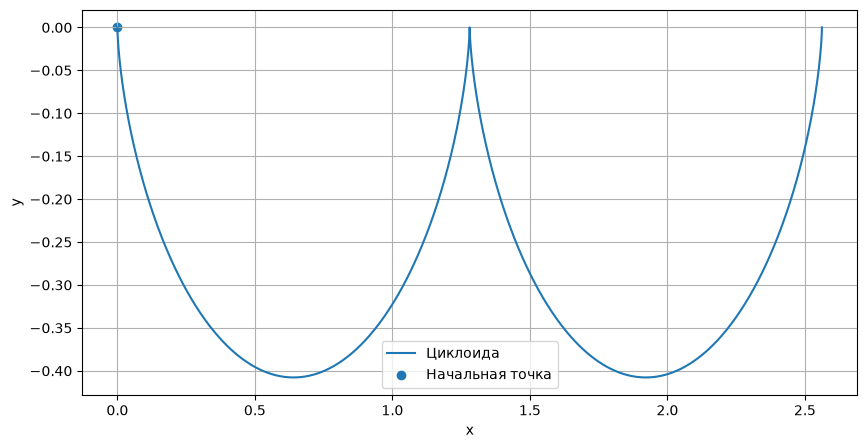

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from matplotlib.widgets import Button

g = 9.81
v0 = 2.0
a = v0**2/(2*g)
theta = np.linspace(0, 4*np.pi, 1000)
x = a*(theta - np.sin(theta))
y = a*(1 - np.cos(theta))

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(x, -y, label="Циклоида")
ax.scatter([x[0]], [-y[0]], label="Начальная точка")
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.grid()
ax.legend()
fig.savefig("листок_3_1_кривая.png", dpi=200, bbox_inches="tight")
plt.show()

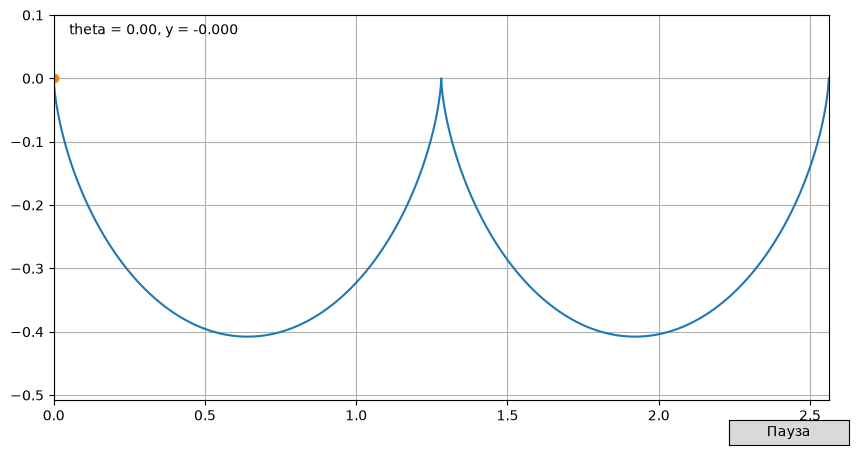

In [2]:
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(x, -y)
point, = ax.plot([], [], "o")
text = ax.text(0.02, 0.95, "", transform=ax.transAxes)
ax.set_xlim(x.min(), x.max())
ax.set_ylim(-y.max()-0.1, 0.1)
ax.grid()

paused = [False]

def update(frame):
    point.set_data([x[frame]], [-y[frame]])
    text.set_text(f"theta = {theta[frame]:.2f}, y = {-y[frame]:.3f}")
    return point, text

def toggle(event):
    paused[0] = not paused[0]

ani = FuncAnimation(fig, update, frames=len(theta), interval=20, blit=True)
button_ax = fig.add_axes([0.8, 0.02, 0.12, 0.05])
button = Button(button_ax, "Пауза")
button.on_clicked(toggle)
plt.show()

## 3.2. Задача о бильярде в прямоугольнике

Пусть прямоугольник имеет стороны $a$ и $b$. Движение между столкновениями равномерное:

$$
x(t)=x_0+v_xt,\qquad y(t)=y_0+v_yt.
$$

При упругом отражении от вертикальной границы меняется знак $v_x$, а от горизонтальной — знак $v_y$.

Метод развертки заменяет отражения продолжением прямой траектории в соседние копии прямоугольника. В исходном прямоугольнике это даёт ломаную траекторию.

Периодичность возникает при рациональном отношении

$$
\frac{v_y/a}{v_x/b}\in\mathbb Q.
$$

При иррациональном отношении траектория не замыкается и равномерно заполняет прямоугольник в смысле движения на соответствующем торе.

Гамильтониан:

$$
H=\frac{p_x^2+p_y^2}{2m},
$$

а между отражениями

$$
\dot x=\frac{p_x}{m},\qquad
\dot y=\frac{p_y}{m},\qquad
\dot p_x=\dot p_y=0.
$$

**Ответ:**

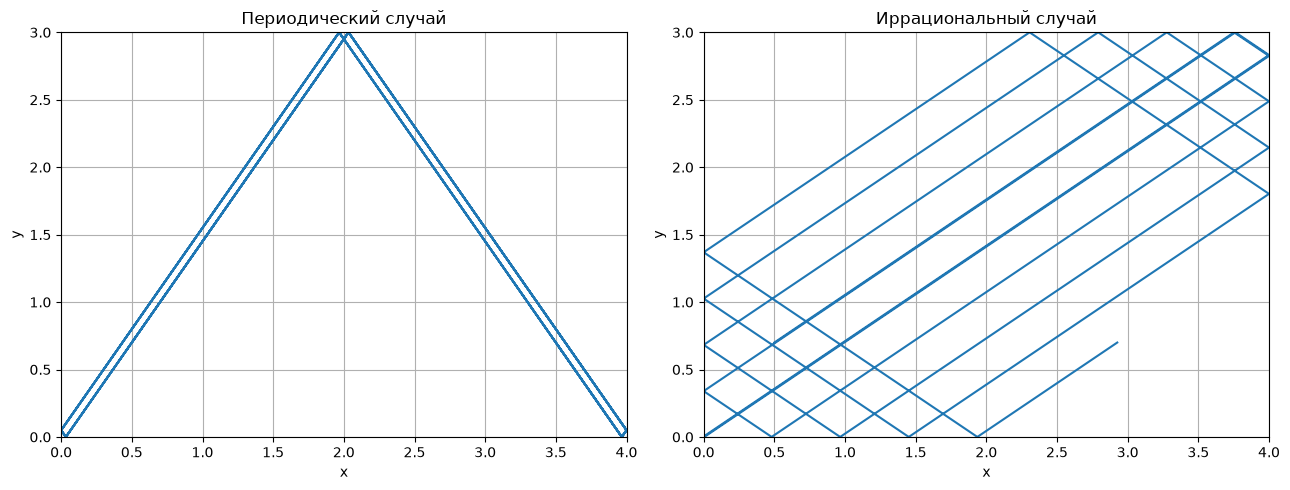

In [3]:
def billiard(a, b, x0, y0, vx, vy, T=30, n=5000):
    t = np.linspace(0, T, n)
    xx = x0 + vx*t
    yy = y0 + vy*t
    xx = a - np.abs(a - np.mod(xx, 2*a))
    yy = b - np.abs(b - np.mod(yy, 2*b))
    return t, xx, yy

a, b = 4, 3
cases = [
    (0.5, 0.7, 1.2, 1.8, "Периодический случай"),
    (0.5, 0.7, np.sqrt(2), 1.0, "Иррациональный случай")
]

fig, axs = plt.subplots(1, 2, figsize=(13, 5))
for ax, (_, _, vx, vy, title) in zip(axs, cases):
    t, xx, yy = billiard(a, b, 0.5, 0.7, vx, vy)
    ax.plot(xx, yy)
    ax.set_xlim(0, a)
    ax.set_ylim(0, b)
    ax.set_title(title)
    ax.set_xlabel("x")
    ax.set_ylabel("y")
    ax.grid()
plt.tight_layout()
fig.savefig("листок_3_2_траектории.png", dpi=200, bbox_inches="tight")
plt.show()

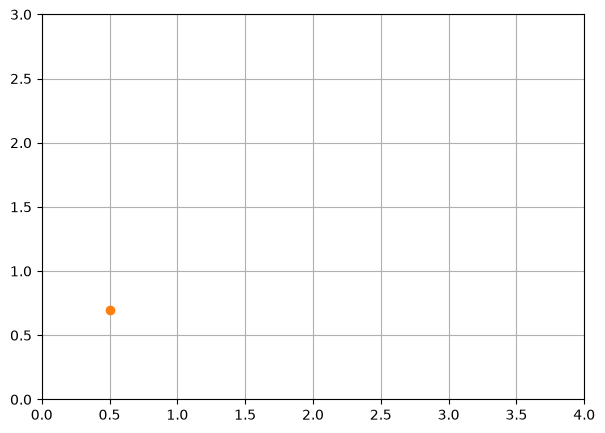

In [4]:
a, b = 4, 3
t, xx, yy = billiard(a, b, 0.5, 0.7, np.sqrt(2), 1.0, T=20, n=1500)

fig, ax = plt.subplots(figsize=(7, 5))
line, = ax.plot([], [])
point, = ax.plot([], [], "o")
ax.set_xlim(0, a)
ax.set_ylim(0, b)
ax.grid()

def update(frame):
    line.set_data(xx[:frame], yy[:frame])
    point.set_data([xx[frame]], [yy[frame]])
    return line, point

ani = FuncAnimation(fig, update, frames=len(t), interval=10, blit=True)
plt.show()

## 3.3. Задача о цепной линии

Рассмотрим однородную тяжёлую нерастяжимую нить. Для элемента цепи условие равновесия приводит к

$$
T\frac{d}{dx}\left(\frac{y'}{\sqrt{1+y'^2}}\right)=\rho g.
$$

После интегрирования:

$$
\frac{y'}{\sqrt{1+y'^2}}=\frac{x}{a},
$$

где $a=T_0/(\rho g)$ — параметр цепной линии.

Отсюда

$$
y'=\frac{x}{\sqrt{a^2+x^2}}.
$$

Ещё одно интегрирование даёт

$$
y=a\operatorname{ch}\frac{x}{a}+C.
$$

При выборе начала координат в нижней точке:

$$
\boxed{y=a\operatorname{ch}\frac{x}{a}}.
$$

Параметр $a$ характеризует отношение горизонтальной составляющей натяжения к весу единицы длины: $a=T_0/(\rho g)$.

**Ответ:**

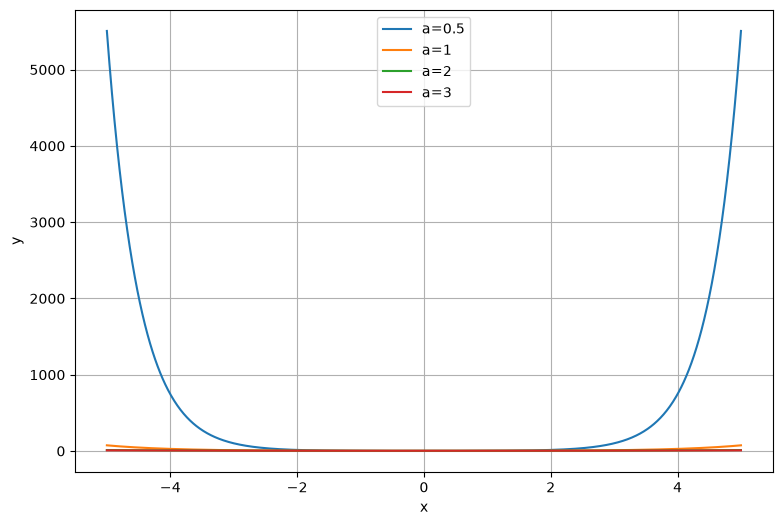

In [5]:
x = np.linspace(-5, 5, 1000)
a_values = [0.5, 1, 2, 3]

fig, ax = plt.subplots(figsize=(9, 6))
for a in a_values:
    ax.plot(x, a*np.cosh(x/a), label=f"a={a}")
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.grid()
ax.legend()
fig.savefig("листок_3_3_цепная_линия.png", dpi=200, bbox_inches="tight")
plt.show()

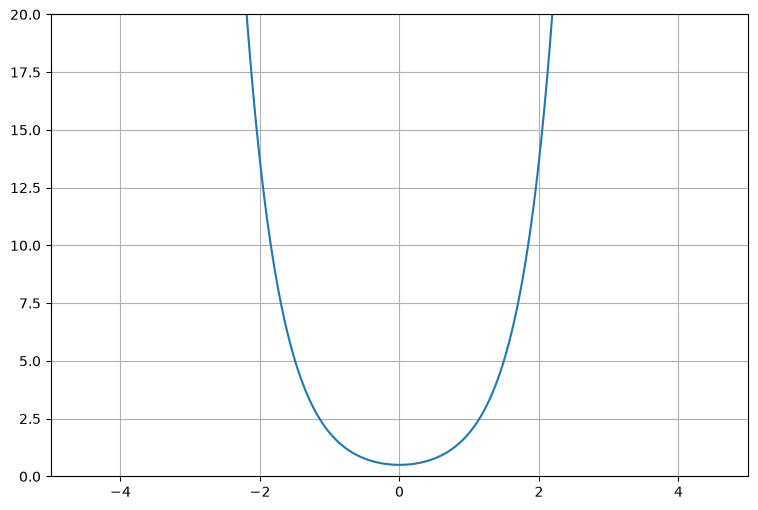

In [6]:
fig, ax = plt.subplots(figsize=(9, 6))
a_values = np.linspace(0.5, 3, 80)
line, = ax.plot([], [])
ax.set_xlim(-5, 5)
ax.set_ylim(0, 20)
ax.grid()

def update(frame):
    a = a_values[frame]
    line.set_data(x, a*np.cosh(x/a))
    return line,

ani = FuncAnimation(fig, update, frames=len(a_values), interval=50, blit=True)
plt.show()

## 3.4. Задача о таутохроне

Таутохронная кривая — кривая, для которой время спуска материальной точки до нижней точки не зависит от начального положения.

Для циклоиды с параметром $a$ параметрические уравнения имеют вид

$$
x=a(\theta-\sin\theta),
\qquad
y=a(1-\cos\theta).
$$

Положим

$$
u=\frac{\theta}{2}.
$$

Тогда

$$
y=2a\sin^2u.
$$

После подстановки в закон сохранения энергии уравнение движения сводится к гармоническому:

$$
\ddot u+\frac{g}{4a}u=0.
$$

Следовательно, время от начальной точки до нижней точки не зависит от амплитуды и равно

$$
\boxed{T_{\text{спуска}}=\pi\sqrt{\frac{a}{g}}}.
$$

Таким образом, циклоида является таутохроной.

**Ответ:**

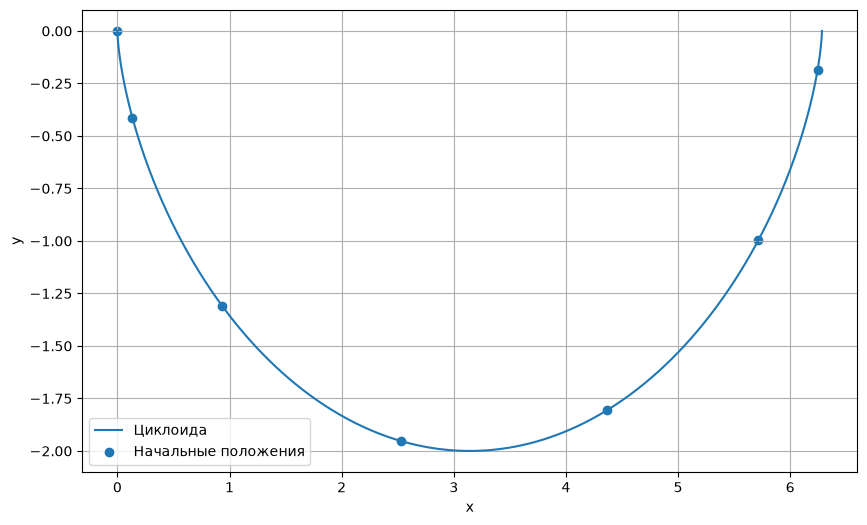

In [7]:
g = 9.81
a = 1.0
theta = np.linspace(0.001, 2*np.pi, 1000)
x = a*(theta - np.sin(theta))
y = a*(1 - np.cos(theta))

fig, ax = plt.subplots(figsize=(10, 6))
ax.plot(x, -y, label="Циклоида")
ax.scatter(x[::150], -y[::150], label="Начальные положения")
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.grid()
ax.legend()
fig.savefig("листок_3_4_циклоиды.png", dpi=200, bbox_inches="tight")
plt.show()

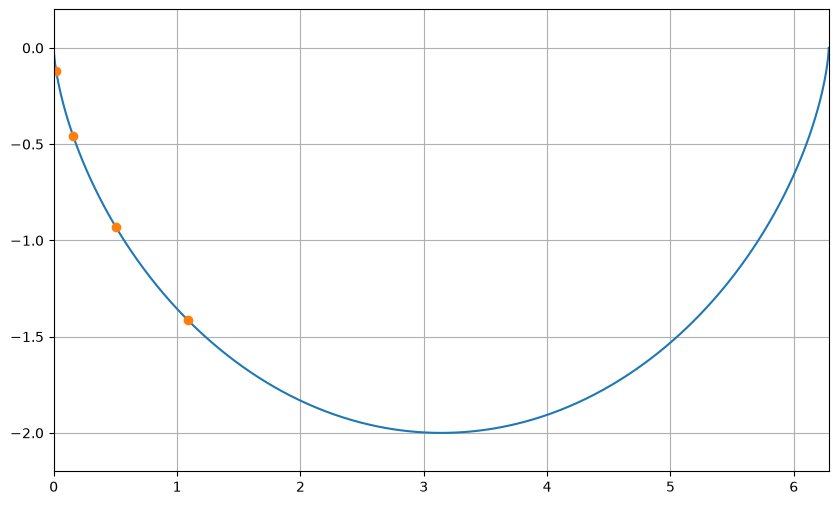

In [8]:
fig, ax = plt.subplots(figsize=(10, 6))
ax.plot(x, -y)
points_x = x[[150, 350, 550, 750]]
points_y = -y[[150, 350, 550, 750]]
points, = ax.plot(points_x, points_y, "o")
ax.set_xlim(x.min(), x.max())
ax.set_ylim(-2.2, 0.2)
ax.grid()

omega = np.sqrt(g/(4*a))
t = np.linspace(0, np.pi/omega, 500)

def update(frame):
    tt = t[frame]
    u0 = np.array([0.25, 0.5, 0.75, 1.0])
    u = u0*np.cos(omega*tt)
    yy = -2*a*np.sin(u/1.0)**2
    xx = a*(2*u - np.sin(2*u))
    points.set_data(xx, yy)
    return points,

ani = FuncAnimation(fig, update, frames=len(t), interval=20, blit=True)
plt.show()

## 3.5. Движение математического маятника

Для математического маятника длины $l$ и массы $m$ второй закон Ньютона даёт

$$
ml^2\ddot\theta=-mgl\sin\theta.
$$

Следовательно,

$$
\ddot\theta+\frac{g}{l}\sin\theta=0.
$$

Для малых углов $\sin\theta\approx\theta$, поэтому

$$
\ddot\theta+\frac{g}{l}\theta=0,
$$

и

$$
\theta(t)=\theta_0\cos\!\left(\sqrt{\frac{g}{l}}\,t\right)
+\frac{\dot\theta_0}{\sqrt{g/l}}\,
\sin\!\left(\sqrt{\frac{g}{l}}\,t\right).
$$

Период малых колебаний:

$$
T_0=2\pi\sqrt{\frac{l}{g}}.
$$

Точная энергия:

$$
E=\frac{1}{2}ml^2\dot\theta^2+mgl(1-\cos\theta).
$$

Отсюда

$$
\dot\theta^2=\frac{2g}{l}\bigl(\cos\theta-\cos\theta_0\bigr)
$$

для колебательного движения. Период конечной амплитуды выражается через полный эллиптический интеграл первого рода:

$$
T(\theta_0)=4\sqrt{\frac{l}{g}}\;K\!\left(\sin^2\frac{\theta_0}{2}\right).
$$

При $\theta_0\to\pi$ период стремится к бесконечности. Фазовый портрет определяется уровенными линиями энергии. Сепаратриса соответствует энергии $E=2mgl$ и разделяет колебания и вращения.

**Ответ:**

$$
T(\theta_0)=4\sqrt{\frac{l}{g}}\;K\!\left(\sin^2\frac{\theta_0}{2}\right).
$$

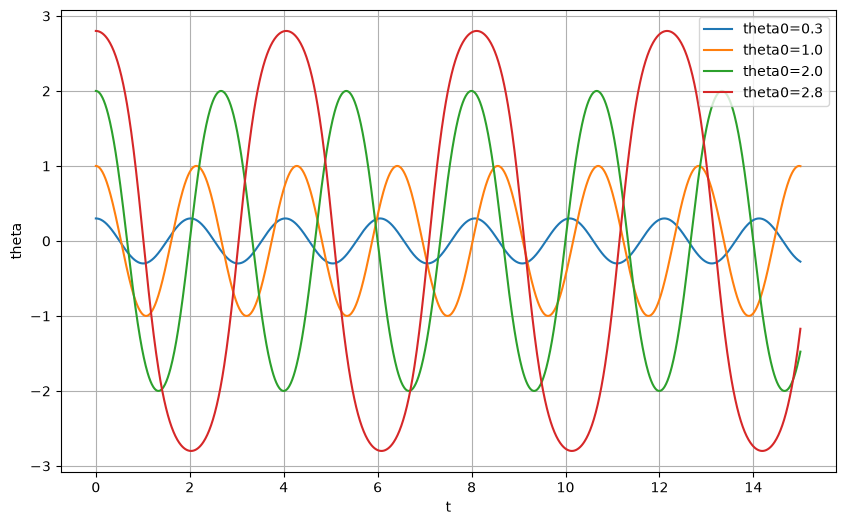

In [9]:
from scipy.integrate import solve_ivp
from scipy.special import ellipk

g = 9.81
l = 1.0

def pendulum(t, state):
    theta, omega = state
    return [omega, -(g/l)*np.sin(theta)]

initial_conditions = [
    (0.3, 0),
    (1.0, 0),
    (2.0, 0),
    (2.8, 0)
]

fig, ax = plt.subplots(figsize=(10, 6))
for theta0, omega0 in initial_conditions:
    sol = solve_ivp(pendulum, [0, 15], [theta0, omega0], max_step=0.01)
    ax.plot(sol.t, sol.y[0], label=f"theta0={theta0}")
ax.set_xlabel("t")
ax.set_ylabel("theta")
ax.grid()
ax.legend()
plt.show()

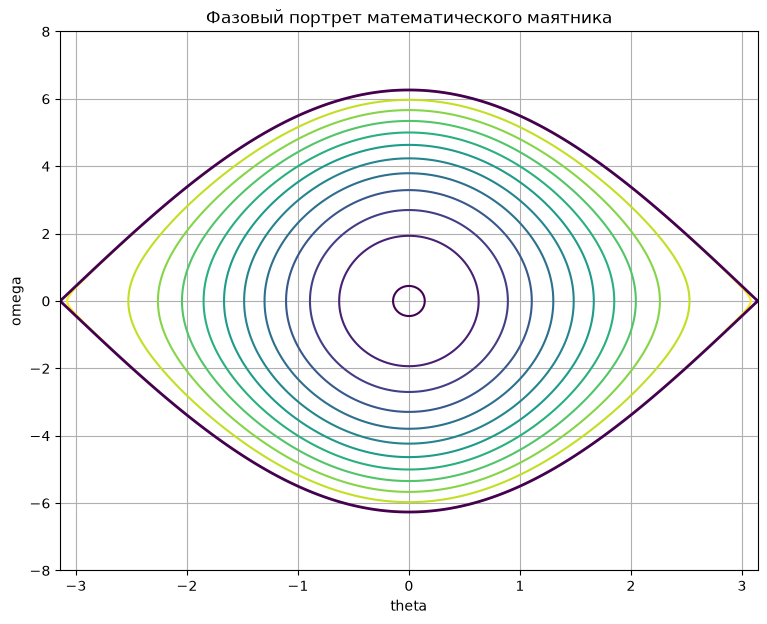

In [10]:
theta = np.linspace(-np.pi, np.pi, 400)
omega = np.linspace(-8, 8, 400)
T, W = np.meshgrid(theta, omega)
E = 0.5*l*l*W**2 + g*l*(1-np.cos(T))

fig, ax = plt.subplots(figsize=(9, 7))
levels = np.linspace(0.1, 2*g*l*0.999, 12)
ax.contour(T, W, E, levels=levels)
ax.contour(T, W, E, levels=[2*g*l], linewidths=2)
ax.set_xlabel("theta")
ax.set_ylabel("omega")
ax.set_title("Фазовый портрет математического маятника")
ax.grid()
plt.show()

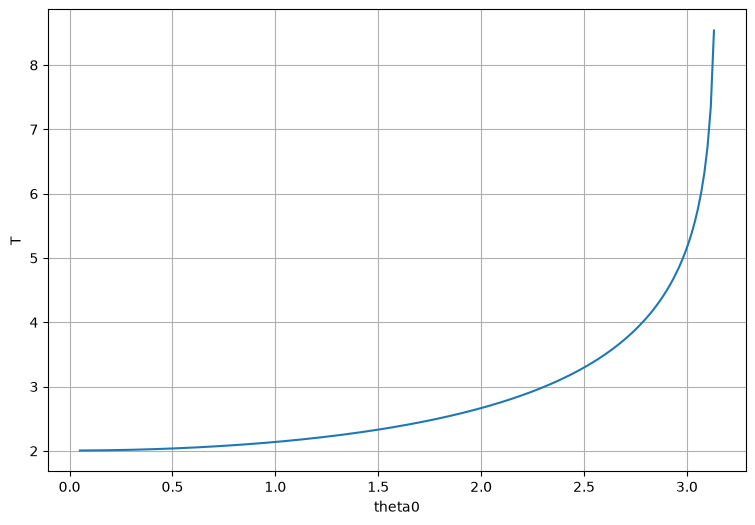

In [11]:
amplitudes = np.linspace(0.05, np.pi-0.01, 200)
periods = 4*np.sqrt(l/g)*ellipk(np.sin(amplitudes/2)**2)

fig, ax = plt.subplots(figsize=(9, 6))
ax.plot(amplitudes, periods)
ax.set_xlabel("theta0")
ax.set_ylabel("T")
ax.grid()
plt.show()

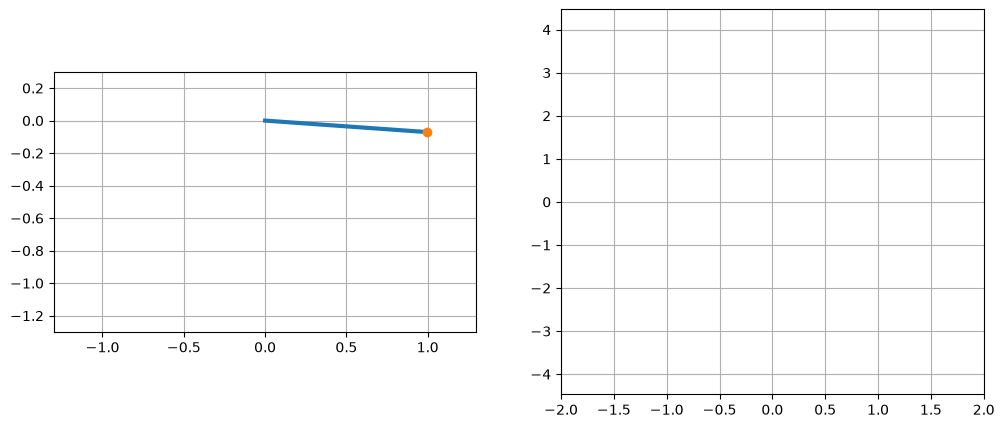

In [12]:
theta0 = 1.5
sol = solve_ivp(pendulum, [0, 15], [theta0, 0], max_step=0.01, dense_output=True)
tt = np.linspace(0, 15, 600)
vals = sol.sol(tt)

fig, axs = plt.subplots(1, 2, figsize=(12, 5))
axs[0].set_xlim(-1.3, 1.3)
axs[0].set_ylim(-1.3, 0.3)
axs[0].set_aspect("equal")
axs[0].grid()

axs[1].set_xlim(-2, 2)
axs[1].set_ylim(vals[1].min()-0.2, vals[1].max()+0.2)
axs[1].grid()

rod, = axs[0].plot([], [], linewidth=3)
bob, = axs[0].plot([], [], "o")
phase, = axs[1].plot([], [])

def update(frame):
    th = vals[0, frame]
    rod.set_data([0, l*np.sin(th)], [0, -l*np.cos(th)])
    bob.set_data([l*np.sin(th)], [-l*np.cos(th)])
    phase.set_data(vals[0, :frame], vals[1, :frame])
    return rod, bob, phase

ani = FuncAnimation(fig, update, frames=len(tt), interval=20, blit=True)
plt.show()